In [3]:
import boto3
import psycopg2
import pandas as pd
# import h3

def funQueryRedshift(strQuery, profileName = "Redshift_Prod"):
    # if the credentials for Redshift have a different profile name,
    # pass it through the profileName parameter

    # Set up AWS Session and access AWS credentials
    session = boto3.Session(profile_name=profileName)
    credentials = session.get_credentials()

    # establish the connection to Redshift
    conn = psycopg2.connect(host="rd_datamart.rdanalytics.cfahome.com",
                      user= 'su.bae',
                      port=5439,
                      password='',
                      dbname="rd_datamart")

    # read the query into a data frame
    dfResult = pd.read_sql(strQuery, con=conn)

    # return the data frame
    return dfResult
pd.set_option('display.max_columns', None)

## Location Attributes

In [4]:
## location metadata
loc = funQueryRedshift("""select * from rd_datamart.conf.location_attributes""", "rd")
loc.head(2)
loc.to_parquet('loc_attributes.parquet')

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [5]:
loc['year'] = loc['opened_dt'].apply(lambda x: str(x)[:4])
loc[loc['year'] == '2026'].sort_values("opened_dt").tail(20)

,location_id,location_number,location_name,is_confidential,status,operator_guid,operator_id,operator,operating_as,is_multi_unit,projected_open_dt,opened_dt,age,is_relocated,relocated_from,is_temp_closed,temp_closed_reason,closed_dt,terminated_dt,concept_type_id,concept_type,location_type_code,subtype_id,subtype,format_type,is_foodtruck,prototype,prototype_edition,building_square_footage,noncustomer_square_footage,total_site_square_footage,total_site_acreage,elevation_meters,elevation_feet,has_sprinkler_system,fire_suppression_method,restaurant_type,deliveries_fulfilled_by,deliveries_fulfilled_for,has_dining_room,maximum_occupancy,has_outside_seating,total_interior_seats,total_exterior_seats,has_cross_parking,total_parking_spaces,total_handicap_spaces,has_drivethru,drivethru_type,has_bypass_lane,has_drivethru_door,total_drivethru_lanes,total_fulfillment_lanes,total_approach_lanes,total_order_points,total_pickup_windows,total_drivethru_capacity,kitchen_type,kitchen_layout,kitchen_installed_dt,has_remote_freezer,playground,land_dimension_notes,is_land_purchased,site_layout,is_mall_food_court,mall_cookline,has_mall_dining_room,has_mall_restroom,has_remote_mall_storage,remote_mall_storage_square_footage,mall_location,address1,address2,address3,city,county,state,zip,zip_extension,country,country_code,hex_id,hex_string,hex_boundary_wkt,latitude,longitude,gmt_offset,timezone,timezone_id,email_address,voicemail_number,phone_number,fax_number,price_group,region_id,region,dma_id,dma,dma_marketing_code,submarket,operator_team_id,operator_team,service_team_id,service_team,is_smart_safe_participant,distribution_center,opportunity_type,building_construction_dt,parent_location_number,accountant_id,accountant_guid,accountant,accounts_receivable_id,accounts_receivable_guid,accounts_receivable,area_director_id,area_director_guid,area_director,business_development_representative_licensee_id,business_development_representative_licensee_guid,business_development_representative_licensee,business_relationship_director_id,business_relationship_director_guid,business_relationship_director,business_relationship_lead_id,business_relationship_lead_guid,business_relationship_lead,dc_existing_restaurant_id,dc_existing_restaurant_guid,dc_existing_restaurant,dc_new_restaurant_id,dc_new_restaurant_guid,dc_new_restaurant,deal_real_estate_developer_id,deal_real_estate_developer_guid,deal_real_estate_developer,digital_field_service_tech_id,digital_field_service_tech_guid,digital_field_service_tech,director_satellite_restaurant_id,director_satellite_restaurant_guid,director_satellite_restaurant,equipment_representative_id,equipment_representative_guid,equipment_representative,erqa_representative_id,erqa_representative_guid,erqa_representative,existing_restaurant_real_estate_developer_id,existing_restaurant_real_estate_developer_guid,existing_restaurant_real_estate_developer,facilities_area_field_consultant_id,facilities_area_field_consultant_guid,facilities_area_field_consultant,facilities_project_coordinator_id,facilities_project_coordinator_guid,facilities_project_coordinator,facilities_regional_director_id,facilities_regional_director_guid,facilities_regional_director,financial_return_consultant_id,financial_return_consultant_guid,financial_return_consultant,fm_tech_consultant_id,fm_tech_consultant_guid,fm_tech_consultant,food_safety_report_representative_id,food_safety_report_representative_guid,food_safety_report_representative,lease_accountant_id,lease_accountant_guid,lease_accountant,new_restaurant_specialist_id,new_restaurant_specialist_guid,new_restaurant_specialist,operations_lead_id,operations_lead_guid,operations_lead,payroll_services_accountant_id,payroll_services_accountant_guid,payroll_services_accountant,payroll_tax_accountant_id,payroll_tax_accountant_guid,payroll_tax_accountant,property_management_analyst_id,property_management_analyst_guid,property_management_analyst,property_tax_accountant_id,property_tax_accountant_guid,property_tax_accountant

In [7]:
from collections import Counter
Counter(loc[loc['year'] == '2026'].subtype)

Counter({'Free Standing Unit': 151,
         'Drive Thru Only': 9,
         'Mall': 6,
         'College': 3,
         'Airport': 3,
         'OCV - Higher Education': 3,
         'Off-site Cooking Location': 2,
         'Office': 2,
         'OCV - Health & Wellness': 1,
         'Delivery Kitchen': 1,
         'Corporate Location': 1,
         'Hospital': 1})

In [8]:
strategy = funQueryRedshift("""
SELECT 
    id AS location_num, 
    location_name, 
    subtype, 
    status AS location_type, 
    strategy_tier AS location_status, 
    state, 
    dma, 
    submarket, 
    region
FROM 
    conf.integrated_strategy
WHERE 
    subtype IN ('FSU', 'DTO')
    AND status IN ('green', 'yellow')
""")
strategy.to_parquet("strategy_attributes.parquet")

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [9]:
pipelines, existing_stores, ownership_map, existing_meta = [], [], {}, {}
for index, row in loc.iterrows():
    pipelines += [{
        "id": row["location_number"],
        "index": index,
        "region": row["region"],
        "store_type": "N",
        "impact_to_existing": {},
    }]
    existing_stores += [{
        "id": row["location_number"],
        "owner": row["operator_id"],
        "opened_dt": row["opened_dt"]
    }]
    existing_meta[row["location_number"]] = (row["opened_dt"], row["subtype_id"])
    if row["operator_id"] not in ownership_map:
        ownership_map[row["operator_id"]] = []
    ownership_map[row["operator_id"]] += [row["location_number"]]

## Simplified Impact Model

In [10]:
query = """
SELECT
    CASE
        WHEN o_store IS NULL THEN o_strategy_id
        ELSE LPAD(o_store::CHAR(5), 5, '0')
    END AS location_num,
    CASE
        WHEN d_store IS NULL THEN d_strategy_id
        ELSE LPAD(d_store::CHAR(5), 5, '0')
    END AS dest_location_num,
    distance_miles AS distance_miles,
    distance_minutes AS distance_mins
FROM 
    sbx_gis.mom_odcm_stores_pipeline_strategy_2
"""
distance = funQueryRedshift(query, 'rd')

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [11]:
distance_matrix = {}
for _, rows in distance.iterrows():
    if rows.location_num not in distance_matrix:
        distance_matrix[rows.location_num] = {}
    if rows.dest_location_num not in distance_matrix:
        distance_matrix[rows.dest_location_num] = {}
    distance_matrix[rows.location_num][rows.dest_location_num] = (rows.distance_miles, rows.distance_mins)
    distance_matrix[rows.dest_location_num][rows.location_num] = (rows.distance_miles, rows.distance_mins)


KeyboardInterrupt



In [24]:
demo = funQueryRedshift("""SELECT 
    DISTINCT
    CASE
        WHEN store IS NULL THEN strategy_id
        ELSE LPAD(store::CHAR(5), 5, '0')
    END AS location_num,
    density_class::int AS density_classification_1,
    competitors AS competitor_count_1
  FROM sbx_gis.mom_primary_market_area_demographics_2
  WHERE distance_from_cfa_location = 1""", "rd")
demo.head(2)

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


,location_num,density_classification_1,competitor_count_1
0,900496B2-7A6E-47E9-89B2-CCE6B024045E,4,21
1,54F4FE9B-C950-482C-BED6-E69C53B9322C,4,6


In [14]:
## impact
impact = pd.read_parquet('distance_output.parquet')
impact.head()

,store1,store2,actual,forecast,opened_dt,distance,error
0,05342,00600,4278832.83,4353872.5,2024-04-04,5.79,-1.754
1,05368,03883,8164730.85,8821020.5,2023-10-19,9.69,-8.038
2,05380,03381,7675561.83,8517464.5,2023-12-14,3.25,-10.969
3,05438,00799,3468272.59,3755820.0,2024-05-16,4.19,-8.291
4,05438,03964,4421752.45,3779517.5,2024-05-16,7.12,14.524


In [15]:
impact_ = pd.merge(impact, demo[['location_num', 'density_classification_1']], left_on='store1', right_on='location_num', how='left')
impact_ = impact_.rename(columns={'density_classification_1': 'density_new'})
impact_ = pd.merge(impact_, demo, left_on='store2', right_on='location_num', how='left')
impact_ = impact_.rename(columns={'density_classification_1': 'density_exist'})
impact_ = impact_.drop(['location_num_x', 'location_num_y'], axis=1)
for c in ['density_new', 'density_exist']:
    impact_ = impact_.fillna(value={c: 0})
    impact_[c] = impact_[c].apply(lambda x: str(int(x)))

In [26]:
from datetime import datetime
from dateutil.relativedelta import relativedelta

output = []
for _, row in impact_.iterrows():
    impacted_store, new_store = row.store2, row.store1
    impacted_store_meta, new_store_meta = existing_meta[impacted_store], existing_meta[new_store]
    if new_store_meta[0] is not None:
        closest, closer = 1000, 0
        boundary, years = [0, 0, 0], [0, 0, 0]
        if impacted_store in distance_matrix:
            for nearby in distance_matrix[impacted_store]:
                if nearby in existing_meta and existing_meta[nearby][0] is not None and existing_meta[nearby][0] < new_store_meta[0]:
                    if existing_meta[nearby][1] in ('FSU', 'DTO'):
                        closest = min(closest, distance_matrix[impacted_store][nearby][0])
                        if distance_matrix[impacted_store][nearby][0] < row['distance']:
                            closer += 1
                        if distance_matrix[impacted_store][nearby][1] // 5 < 3 :
                            boundary[int(distance_matrix[impacted_store][nearby][1] // 5)] += 1
                        diff = int((new_store_meta[0] - existing_meta[nearby][0]).days // 365)
                        if diff < 3:
                            years[diff] += 1
            closest = [0, 1][row['distance'] < closest]
        else:
            print(impacted_store)
            closest = 1
        output += [[row.store1, row.store2, row.forecast, row.opened_dt[:4], row.distance, row.density_new, row.density_exist, row.competitor_count_1] 
                   + boundary + years + [closest, closer] + [row.error]]

NameError: name 'impact_' is not defined

In [17]:
import numpy as np
output_df = pd.DataFrame(output, columns=['store1', 'store2', 'forecast', 'open_year', 'distance', 'density_new', 'density_exist', 'competitor_count_1', 'boundary_1', 
                                          'boundary_2', 'boundary_3', 'year_1', 'year_2', 'year_3', 'closest', 'closer_stores', 'error'])
output_df = output_df.replace([np.inf, -np.inf], np.nan)
# drop extremes
output_df = output_df[(output_df['error'] >= -40) & (output_df['error'] < 20)]

output_df = output_df.dropna()

In [18]:
output_df.head()

,store1,store2,forecast,open_year,distance,density_new,density_exist,competitor_count_1,boundary_1,boundary_2,boundary_3,year_1,year_2,year_3,closest,closer_stores,error
0,05342,00600,4353872.5,2024,5.79,7,6,17.0,0,0,0,0,5,2,1,0,-1.754
1,05368,03883,8821020.5,2023,9.69,6,6,10.0,0,0,1,2,0,1,0,3,-8.038
2,05380,03381,8517464.5,2023,3.25,6,6,10.0,0,0,0,0,2,0,1,0,-10.969
3,05438,00799,3755820.0,2024,4.19,4,4,35.0,0,1,3,12,7,5,0,1,-8.291
4,05438,03964,3779517.5,2024,7.12,4,5,19.0,0,0,4,12,7,5,1,0,14.524


In [19]:
output_df.shape

(1009, 17)

In [20]:
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
X, y = output_df[['forecast', 'open_year', 'distance', 'density_new', 'density_exist', 'competitor_count_1', 'boundary_1', 
             'boundary_2', 'boundary_3', 'year_1', 'year_2', 'year_3', 'closest', 'closer_stores']].values, output_df['error'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

model = CatBoostRegressor(
        iterations=300,
        learning_rate=0.005,
        depth=5,
        loss_function='RMSE',
        random_seed=42,
        bootstrap_type='No'
    )
categorical_feature_indices = [3, 4]
model.fit(X_train, y_train, eval_set=(X_test, y_test), verbose=100)

predictions = model.predict(X_test)

from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

r_squared = r2_score(y_test, predictions)
rmse = mean_squared_error(y_test, predictions)
mape = mean_absolute_percentage_error(y_test, predictions)
print("--- Model Performance on Test Data ---")
print(f"R-squared (R²): {r_squared:.4f}")
print(f"RMSE: {rmse}")
print(f"MAPE: {mape}")

0:	learn: 12.0832129	test: 11.8242570	best: 11.8242570 (0)	total: 135ms	remaining: 40.5s
100:	learn: 11.3314363	test: 11.3316596	best: 11.3316596 (100)	total: 285ms	remaining: 561ms
200:	learn: 10.8925771	test: 11.1316614	best: 11.1316614 (200)	total: 431ms	remaining: 212ms
299:	learn: 10.5968236	test: 11.0304772	best: 11.0304772 (299)	total: 576ms	remaining: 0us

bestTest = 11.03047719
bestIteration = 299

--- Model Performance on Test Data ---
R-squared (R²): 0.1235
RMSE: 121.67142603057793
MAPE: 2.2375243568411465


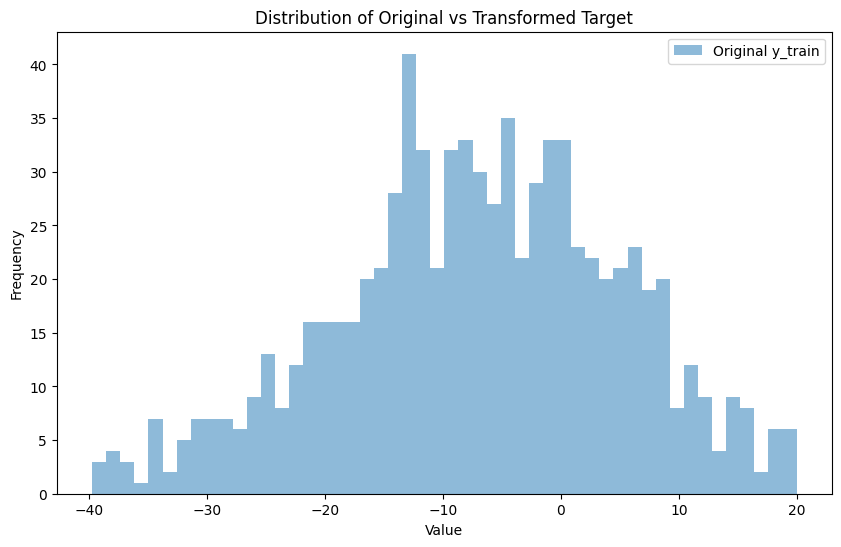

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(y_train, bins=50, alpha=0.5, label='Original y_train')
# plt.hist(y_train_transformed, bins=50, alpha=0.5, label='Transformed y_train')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Original vs Transformed Target")
plt.legend()

plt.show()

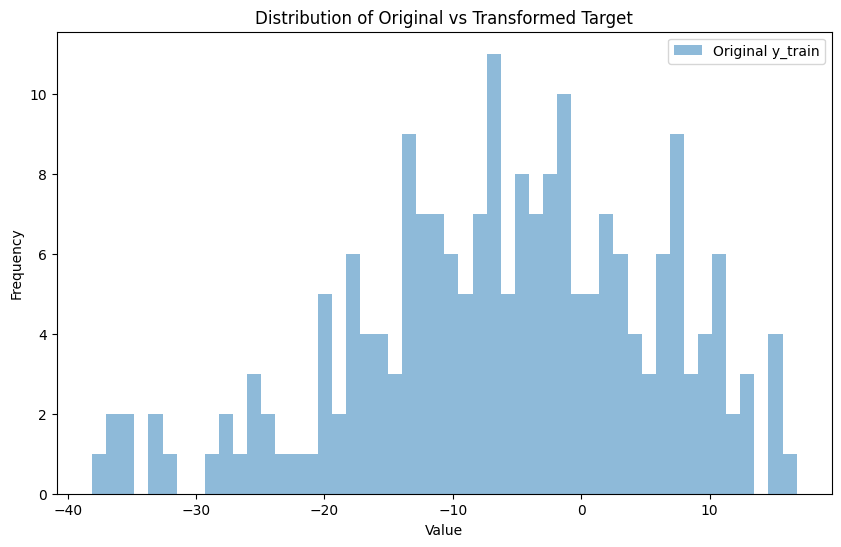

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(y_test, bins=50, alpha=0.5, label='Original y_train')
# plt.hist(y_train_transformed, bins=50, alpha=0.5, label='Transformed y_train')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Original vs Transformed Target")
plt.legend()

plt.show()

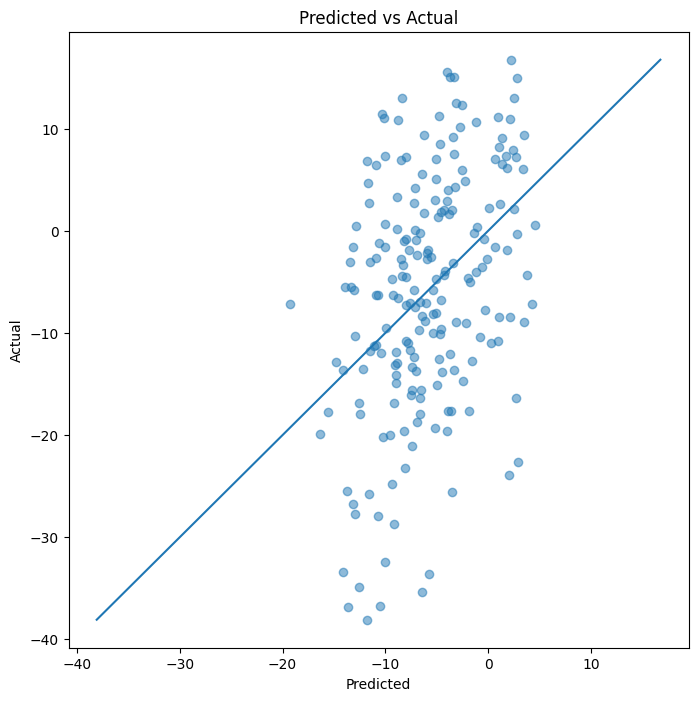

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.scatter(predictions, y_test, alpha=0.5)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Predicted vs Actual")

# diagonal reference line
min_val = min(min(predictions), min(y_test))
max_val = max(max(predictions), max(y_test))

plt.plot([min_val, max_val], [min_val, max_val])
plt.show()

## Sales

In [92]:
monthly_sales = funQueryRedshift(
"""
SELECT
    DATE_TRUNC('month', pos_business_dt)::DATE AS month,
    location_id as location_number,
    SUM(total_amt) AS total_net_sales,
    SUM(total_transactions) AS trans_cnt
FROM restaurant_performance.sales_qtr_hour_intervals
WHERE pos_business_dt >= '2016-01-01'
GROUP BY
    DATE_TRUNC('month', pos_business_dt)::DATE,
    location_id
ORDER BY
    location_id,
    month;
""",
'rd')
monthly_sales["location_number"] = monthly_sales["location_number"].apply(lambda x: str(x).zfill(5))
monthly_sales['month'] = pd.to_datetime(monthly_sales['month'])
monthly_sales.head()

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


,month,location_number,total_net_sales,trans_cnt
0,2018-05-01,00000,20.00,2
1,2018-06-01,00000,2434.90,166
2,2018-07-01,00000,6161.10,230
3,2018-08-01,00000,4652.99,229
4,2018-09-01,00000,4946.35,182


In [93]:
monthly_sales = pd.merge(monthly_sales, loc[["location_number", "opened_dt", "status", "location_type_code"]], on="location_number", how="left")

In [100]:
monthly_sales[monthly_sales['location_num'] == '01864'].tail()

,location_num,open_date,location_status,location_type,month,total_net_sales,trans_cnt
94889,01864,2006-03-02,closed,FSU,2025-05-01,1197165.23,67166
94890,01864,2006-03-02,closed,FSU,2025-06-01,1046914.43,59551
94891,01864,2006-03-02,closed,FSU,2025-07-01,1117901.95,63536
94892,01864,2006-03-02,closed,FSU,2025-08-01,1141778.16,64209
94893,01864,2006-03-02,closed,FSU,2025-09-01,458366.48,26620


In [96]:
monthly_sales = monthly_sales[["location_number", "opened_dt", "status", "location_type_code", "month", "total_net_sales", "trans_cnt"]]
monthly_sales.columns = ["location_num", "open_date", "location_status", "location_type", "month", "total_net_sales", "trans_cnt"]
monthly_sales.to_parquet("monthly_sales.parquet")

In [53]:
# SELECT 
#     location_num, 
#     date_trunc('month', trans_date) AS month, 
#     sum(sls_net) AS monthly_sales, 
#     count(distinct trans_date) as trans_count,
#     sum(trans_cnt) AS monthly_trans 
# FROM 
#     dx_prod.restfin_lh.daily_sales_extended 
# WHERE 
#     trans_date >= date('2016-01-01') 
#     and trans_date < date_trunc('month', current_date)
# GROUP BY 1, 2
import pandas as pd
sales = pd.read_parquet("monthly_sales.parquet")
print(min(sales.month), max(sales.month), set(sales.location_status))

2001-08-01 2026-05-01 {'closed', 'open', 'None'}


In [54]:
sales.head(2)

,location_num,open_date,location_status,location_type,month,total_net_sales,trans_cnt
0,03888,2018-05-10,open,FSU,2023-12-01,990108.50,59108
1,00801,1986-04-16,open,FSU,2020-01-01,666952.25,71002


In [55]:
pipeline_sales = pd.read_csv("sales_forecast_pipelines.csv")
pipeline_sales["location_status"] = "future"
pipeline_sales = pipeline_sales[["location_num", "open_date", "location_status", "location_type", "forecast_annual_sales"]]
pipeline_sales['location_num'] = pipeline_sales['location_num'].apply(lambda x: str(int(x)).zfill(5))
pipeline_sales.head(3)

,location_num,open_date,location_status,location_type,forecast_annual_sales
0,06980,2029-06-07,future,pipeline,8.728337e+06
1,06989,2029-06-07,future,pipeline,7.789594e+06
2,06988,2028-08-03,future,pipeline,6.722737e+06


In [56]:
sales['year'] = sales['month'].apply(lambda x: str(x)[:4])
sales = sales.groupby(['location_num', 'year']).agg(annual_sales=('total_net_sales', 'sum'), count=('month', 'count'))

In [57]:
sales = sales.reset_index()

In [58]:
sales_by_store = {}
for _, row in sales.iterrows():
    sales_by_store[row.location_num] = round(row.annual_sales / int(row["count"]) * 12, 2)
for _, row in pipeline_sales.iterrows():
    sales_by_store[row.location_num] = round(row.forecast_annual_sales, 2)

In [59]:
import pickle
with open('sales_by_store.pkl', 'wb') as f:
    pickle.dump(sales_by_store, f)

## Features

In [60]:
import pickle
with open('distance_matrix.pkl', 'rb') as f:
     distance_matrix = pickle.load(f)

In [13]:
sites_ = funQueryRedshift("""select * from conf.integrated_strategy""", "rd")
sites_.head()

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


,id,location_name,status,strategy_tier,comment,subtype,trade_area_rank,latitude,longitude,state,region,dma,submarket,country,strategist,real_estate_developer,eval_ts,created_by,created_ts,last_edited_by,last_edited_ts,is_build_to_suit,is_ssam,time_to_real_estate_committee,real_estate_committee_year,real_estate_committee_probability
0,6D9D4B9F-6E5D-4FE9-B0D7-2D740B11356E,"Moberly, MO",drafts,None,SL: Check population and FAFH. Highway Option?,FSU,NaN,39.444108,-92.424214,MO,Midwest Region,"Columbia-Jefferson City, MO",N/A,United States,2099898,Chris Tyndal,2023-02-28 04:40:34,GIS,2024-09-02 00:15:46,ADMIN,2026-08-09 18:24:16,No,Yes,None,None,None
1,E8D45AF9-50CC-481D-9B5E-49448CA71CDC,Robert Smalls Pkwy and Parris Island Gateway,drafts,None,None,FSU,NaN,32.425577,-80.728406,SC,Atlantic Region,"Savannah, GA",N/A,United States,Albert Yang,Giancarlo Jimenez,1899-12-30 00:00:00,GIS,2024-09-02 00:15:46,ADMIN,2026-08-09 18:24:16,No,No,None,None,None
2,F8ECBE48-51D2-4456-B643-3A0ED0C14838,South Campus,drafts,Tier 3,Downgraded to Draft in Jan 26. Tops is only re...,FSU,3.0,43.021532,-76.109764,NY,Northeast Region,"Syracuse, NY","Syracuse, NY | Metro & East Syracuse",United States,Paul Foster,Elizabeth Meloy,2021-05-10 04:00:00,GIS,2024-09-02 00:15:46,ADMIN,2026-08-09 18:24:16,No,No,None,None,None
3,C55349C1-57AB-45F3-9DF2-81BAC5296B1D,"Walton, KY",drafts,None,"Kroger, TB, McD, Kohl's, FLying J, Beans",FSU,NaN,38.858638,-84.622949,KY,Midwest Region,"Cincinnati, OH",N/A,United States,Scott Lail,Giancarlo Jimenez,2022-03-17 16:09:15,GIS,2024-09-02 00:15:46,ADMIN,2026-08-09 18:24:16,No,No,None,None,None
4,660BBD8C-FDDA-4570-ABFB-367874CAADC2,"Pontiac, IL",drafts,None,None,FSU,NaN,40.873559,-88.666364,IL,Midwest Region,"Peoria-Bloomington, IL",N/A,United States,2099898,Chris Tyndal,2023-10-25 04:00:00,GIS,2024-09-02 00:15:46,ADMIN,2026-08-09 18:24:16,None,Yes,None,None,None


In [14]:
set(sites_.strategy_tier)

{'Focus', None, 'Tier 1', 'Tier 2', 'Tier 3'}

In [31]:
sites.head()

NameError: name 'sites' is not defined

In [61]:
## reading data source for existing and future stores

# sites
sites = pd.read_csv("rd-integrated-strategy-2025-08-21.csv")
sites["location_number"] = sites["GlobalID"].apply(lambda x: x.replace('{','').replace('}',''))

# strategy dots
query = """select * from sbx_gis.mom_location_pipeline_strategy_2 where pipeline_status = 'Active Deal'"""
strategy = funQueryRedshift(query, 'rd')

# remove active deals from sites
active_deals = []
for _, row in sites[['location_number', 'NAME', 'LATITUDE', 'LONGITUDE']].iterrows():
    for _,row_ in strategy[['name', 'latitude', 'longitude']].iterrows():
        distance = haversine_distance(row.LATITUDE, row.LONGITUDE, row_.latitude, row_.longitude)
        if distance < 0.2: # less than 0.2 miles
            # print(row.NAME, row.location_number, row_['name'], distance)
            active_deals += [row.location_number]
            break
print(active_deals)
# active_deals = ['307B85FC-5CE1-424C-8F73-02D08C588961', '2167129F-4267-4D8B-ADDD-041675C14265', '947B5C9F-1471-423E-B863-06264D851666', 'AA021BCB-D508-44E0-9A03-06BA8180BDBB', 'F70F93B8-B199-4DEF-8B26-07096A2324CE', '9B8AB33C-2F37-484D-BE40-07CF13CF1834', '934B48BE-6DF8-4D2A-815F-0986583D0AAB', 'DA778FA8-5C95-445D-B8F7-09DF52EC41E3', '25DDE2E4-F7CA-4B15-A6B7-0B178D2A6F1F', '7CCC7A6D-F168-45FB-9AC4-0C00E50018F3', '4DF0241B-A00D-421F-AFF8-0D220335947F', '56E1C0E9-8BC8-48EA-8833-0D64A30D045D', 'BDC0468B-7852-4ECE-9365-0DC1C200773A', '0CEF0689-D36E-4964-BD41-0DE01F3BC876', '1F408185-BB30-4D83-BA5C-19F7BEB11E72', 'D8AF022B-A132-44FB-994C-1A58EB09168A', 'DFC8E7FA-F349-4CFF-8577-1D307A09AA95', '2659756D-16EA-4856-85E9-2099A61EEA7E', 'F027A3D4-ADDF-499D-B8B9-21326BCAD6C3', 'B211DF79-706B-404A-907E-2176472001A1', '4EFDF236-B84F-4178-A8D2-251A7262F695', 'A0B9463A-8129-4738-BD27-2607A1160813', '88EF7017-8866-452D-9800-26FA0CE14C01', '1F4C19D2-E147-4F74-AFA1-274509C2AE79', '3314AA47-3F12-4B5B-B353-276BE9A5BBB6', 'A50C6417-236A-4729-B3DF-28F273E4225E', '03032B4A-46E0-459C-91A2-2A650AAB3DA8', '9215BF01-870B-4FB3-8C2A-2A99532D6992', '084E0F47-57AB-4FB2-8A1F-2B2275D1B46E', 'FCDE3F19-B87B-4AEB-B440-2E5691B99011', 'DB08D284-245C-4E3F-B1A3-2E767EBC4F0D', '9DBA1D47-1ED2-41E9-A392-2EB64A5D8E07', '6FE5009C-0FA9-4EA9-A855-2F3056B65DA4', 'B323F477-5BA5-4680-8A2A-2F535D4AAC5B', '040545BC-3E4A-4A50-9B5D-302B7BD8DC7C', '7DEBB30C-FD3A-4B12-AF89-309360DF8B0F', 'E36FD920-706A-45C2-8E8F-3128F68E2777', '493CECEA-D2BC-48C8-8F59-3256087A5B72', '34032BC1-61BE-400A-B690-35989C876D46', '71B8C452-C6A9-4B99-BDB4-37FCB35C7C69', '9C7D728D-A823-40AD-B837-3951C6E9E184', '56D9C99E-72A3-49DE-85D4-3C4F79401187', 'E7A0C653-E646-4C35-84B6-3CD5CA125AA6', '6BC791C4-1A6D-48FB-A246-3DAB0990CB27', '4479805D-C2C3-4B7B-8173-414063497294', '85BF54CD-1A52-4601-AA48-41F7AE0E1B44', '804032C6-A01D-4D28-A63F-42CA28C79CF8', '0D9F1C59-9E79-4FD0-99A2-4473583F909E', 'E4119D39-68A6-4F61-ABC4-4558C1B0C105', '3FE35134-2D7F-4AD3-844C-474C58DBC82B', '72130A87-7110-4AFA-915C-484D0E5AC1CA', '2768F508-F021-4C62-A8CF-48EA66049F83', '11D7C483-9155-4DB6-9141-4C72F1D8E522', '995E1239-3CBC-4450-B76F-4D94AF2339D2', '35287C51-8798-44A7-8FB5-4E3D72259558', '63E1A4DD-B348-48BF-839D-50BEBF37FCD4', 'C6F3149D-403F-4156-8D59-52C2A6C13D01', '59F39D16-1CC3-4A2B-A884-58D5FC5BA023', 'E959B419-36A1-4DA2-AB61-5A8F18F212EA', '0B34C1F3-37EA-47D6-BFC2-5ACDA265538B', '9AB55144-9722-4B39-B1A5-5D6BA95AA998', 'DD1287E3-DB5F-49BB-9E96-5DF16290C550', 'A5DC82A4-FE4C-43E1-9F00-605A38E1C180', 'F43D50CE-2343-4C42-9338-642D4D4E05C6', 'B1F96443-D52D-47D6-B6D5-65FFBD687DE0', 'A501EBDA-26B3-4F3A-AC88-68918E6D9253', '1B6F5F19-5828-4936-A235-6B5203D6B6A0', 'DFC403E1-A44B-4A33-82D7-700E1C9BB694', 'A8CF5BDF-1980-4C0D-A27A-709273EAB9A1', 'B32258DA-7D68-4078-A6AE-73A569CCBA7E', '58D5459F-28E8-4AAF-9594-73DE5B418C00', '725F859A-EEA3-4702-981B-74F7A866B1CC', '15ACDF64-7E00-47F7-BBAD-83644DE92CCE', '23E85CD7-21CC-4585-8849-8DD3F73F3721', '7D256F5E-2349-44DB-BC41-8F2F50B28812', 'A48C844F-9B46-4868-BD6C-8FECF5B54B83', '0BD7B4A1-B3BF-423B-BAFD-8FEE2DADCE1C', 'AFDF22AC-C5FA-47C0-AF75-92056838D412', 'EF268BCA-A839-4E5F-8E6F-92119E0186AC', '43899368-AD28-4915-9BDC-9429D9CC919B', '510BBCAD-747F-4629-AA3C-94D928C09208', 'A7624FA1-BA04-4C47-BD86-9815FB49696C', 'BB9920C7-06C5-4B52-AC22-9D3061541B36', 'FBA64C2A-1EB5-4A63-9EF8-9FA4E5FF6FC3', 'F63C469B-442F-4430-A7CB-A024C6A9F8AE', '8902861A-D7EF-4C97-B6ED-A07D34805B43', 'CA983B84-7E1A-4EB4-8B3E-A2795CF6D6EB', '946F42B0-84E8-462F-A61C-A2DC58E42DF6', '9408D78E-5D99-4818-8EBC-A5575A8B85AF', '3ADCDCFD-A4BF-499B-8DC5-A6E64D13037C', '1110C136-3AEF-4584-AD23-A9680A9DD463', '0050955A-F423-4CDC-BBCE-AB54011C37B9', 'B417D27C-EBCA-4BC2-AADA-ACB675253728', 'EA561BDC-57A1-43F0-ACD2-ACE6834876B5', '5B01B35A-F816-4A79-8D86-ACEC31C2AB85', 'E3453E1D-2A74-4FDC-91CD-B0FAABC9B89D', 'A63D0505-468F-4369-BE8D-B54959475D65', 'EF203C7C-4567-439D-ABCB-C0ED23D96BE6', 'F6FC0B84-F7F9-4C8C-9A83-C2097A5CBCEF', '72255608-A1EE-46B3-8115-C214F9A4114B', '917FDB9D-7A01-4B56-B308-C54991D5DADA', '673F4574-820E-47EB-9A21-C7AF922428BA', '65EEF69A-7FE4-4D9A-BAE0-CC5FC684DDFE', 'C16A88A9-F8EE-423C-A78A-CC9BF0E58DE6', 'A77E2F8A-1C3E-45BD-9726-CFE5F65448F5', 'C0F35438-074E-477D-BAD5-D1C439E57FEF', '1C227A0E-7145-4978-BBB7-D59A90B43FCB', '3866B30F-715A-43AA-825D-D5DB2DD1C287', '5CAB14B4-D28E-42BF-9CF2-D74C6FDDF87C', '7FA7A705-E7B9-4948-A104-D7C15E84EAB6', 'DF0AC036-0F64-4DA4-A674-D832DCC8C812', 'CD575890-3971-42CA-B536-DB4E6006FBE2', '27C8C28B-AA60-43E1-994B-DC10B08711FC', '1B464F95-7F32-4223-9A86-E054FB3D6D37', '738D2615-69B8-4E94-B855-E15C98B5129E', '5608061F-1EC2-4805-B3B2-E1676485D2C1', '7BBFAA14-8693-4D82-91E9-E17F98FB3558', 'EAED373D-4A98-4940-BC49-E87872F56DA9', 'B71305AD-201E-48E8-A6A8-EBBC90FD8E32', '7BADE619-8E6D-4C60-A21E-EC5020373CC3', '31544674-F33E-4153-856B-EC925701741C', '9E0D9DA4-42E2-45AA-B603-F05BCDC21D20', 'EDA7079F-F50A-472B-81AE-F265AE3C9F76', 'FBD6445B-A65A-41C3-9298-F621D7DD68E8', '59A9B640-E58D-4A28-9764-F73FA6C8E472', 'BEEA5BCA-3828-4A5F-BE5F-FA117D08B00B', '0A629C77-5838-4156-9DD8-FBE1EB18EBDE']

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


['307B85FC-5CE1-424C-8F73-02D08C588961', '2167129F-4267-4D8B-ADDD-041675C14265', '947B5C9F-1471-423E-B863-06264D851666', 'AA021BCB-D508-44E0-9A03-06BA8180BDBB', 'F70F93B8-B199-4DEF-8B26-07096A2324CE', '9B8AB33C-2F37-484D-BE40-07CF13CF1834', '934B48BE-6DF8-4D2A-815F-0986583D0AAB', '25DDE2E4-F7CA-4B15-A6B7-0B178D2A6F1F', '7CCC7A6D-F168-45FB-9AC4-0C00E50018F3', '4DF0241B-A00D-421F-AFF8-0D220335947F', '56E1C0E9-8BC8-48EA-8833-0D64A30D045D', 'BDC0468B-7852-4ECE-9365-0DC1C200773A', '0CEF0689-D36E-4964-BD41-0DE01F3BC876', '1F408185-BB30-4D83-BA5C-19F7BEB11E72', 'D8AF022B-A132-44FB-994C-1A58EB09168A', 'DFC8E7FA-F349-4CFF-8577-1D307A09AA95', '2659756D-16EA-4856-85E9-2099A61EEA7E', 'F027A3D4-ADDF-499D-B8B9-21326BCAD6C3', 'B211DF79-706B-404A-907E-2176472001A1', '50A8B0C5-DD2A-4538-9896-25060F867298', '4EFDF236-B84F-4178-A8D2-251A7262F695', 'A0B9463A-8129-4738-BD27-2607A1160813', '88EF7017-8866-452D-9800-26FA0CE14C01', '1F4C19D2-E147-4F74-AFA1-274509C2AE79', '3314AA47-3F12-4B5B-B353-276BE9A5BBB6',

In [62]:
existing_meta = {}
for index, row in loc.iterrows():
    opening_date = row["projected_open_dt"] if row["status"] == "future" else row["opened_dt"]
    existing_meta[row["location_number"]] = (opening_date, row["subtype_id"])

## sales forecast 

In [63]:
categorical = [
    "dma",
    "density_classification_1",
    "month_of_opening",
    "ssam_flag",
    "no_dt_flag",
    "subtype",
]
target = "avg_monthly_sales_log"
integer = [
    "total_population_1",
    "worker_population_1",
    "daytime_population_1",
    "total_households_1",
    "competitor_count_1",
    "boundary_5",
    "boundary_10",
    "boundary_15",
    "boundary_20",
    "boundary_25",
    "boundary_30",
    "months_6m",
    "months_12m",
    "months_18m",
    "months_24m",
    "months_30m",
    "months_36m",
]
numerical = [
    "avg_population_growth_1",
    "total_households_per_sq_mile_1",
    "med_household_income_1",
    "med_disposable_income_1",
    "avg_disposable_income_1",
    "annual_budget_expenditure_1",
    "annual_budget_expenditure_index_1",
    "med_home_value_1",
    "avg_home_value_1",
    "food_away_from_home_1",
    "bigbox_1",
    "bigbox_2",
    "bigbox_3",
    "competitor_1",
    "competitor_2",
    "competitor_3",
    "highway_5",
    "highway_10",
    "highway_5min",
    "highway_10min",
    "close_highway_dist",
    "avg_monthly_sales_closest_1year",
    "growth_rate_closest",
    "avg_monthly_sales_mean_1year",
    "growth_rate_mean",
    "avg_monthly_sales_25th_1year",
    "growth_rate_25th",
    "avg_monthly_sales_75th_1year",
    "growth_rate_75th",
]
traffic = [
    "median_average_daily_traffic_1",
    "max_average_daily_traffic_1",
    "median_average_daily_traffic_2",
    "max_average_daily_traffic_2",
    "median_average_daily_traffic_3",
    "max_average_daily_traffic_3",
]

In [64]:
## sales forecast
from catboost import CatBoostRegressor, Pool
import numpy as np

# Load model
model_mean = CatBoostRegressor()
model_mean.load_model("sales_forecast_model_.cbm")
model_lower = CatBoostRegressor()
model_lower.load_model("sales_forecast_model_l.cbm")
model_median = CatBoostRegressor()
model_median.load_model("sales_forecast_model_m.cbm")
model_upper = CatBoostRegressor()
model_upper.load_model("sales_forecast_model_u.cbm")

features = pd.read_csv("sales_batch_output_4year.csv")

features_ = features.copy()
features_[integer] = features_[integer].astype(int)
features_[categorical] = features_[categorical].astype(str)
features_[numerical] = features_[numerical].astype(float)
features_[traffic] = features_[traffic].astype(float)
feature_list = categorical + numerical + traffic
x = features_[feature_list].values.reshape(-1, len(feature_list))

sales_range_2028 = {}
for index, row in features_.iterrows():
    year = int(str(row.opened_dt)[:4])
    if year == 2028:
        low, mid, high = model_lower.predict(x[index]), model_median.predict(x[index]), model_upper.predict(x[index])
        sales_range_2028[row.location_num] = (np.exp(low)*12, np.exp(mid)*12, np.exp(high)*12)

## Build out cost
build_out_cost_by_region = {'Atlantic Region': {'avg_pct_change': 20.70117896976387,
  'last_mean': 4790833.241538461,
  'last_median': 5319967.99,
  'std': 1635191.1907595405 / 2},
 'Midwest Region': {'avg_pct_change': 13.433963230558328,
  'last_mean': 5630067.5424,
  'last_median': 5536303.74,
  'std': 585191.9791360076},
 'Northeast Region': {'avg_pct_change': 12.143127494548215,
  'last_mean': 6356554.516428572,
  'last_median': 6028749.255,
  'std': 1142610.4311770445/2},
 'Southeast Region': {'avg_pct_change': 13.575353503908829,
  'last_mean': 4912179.8963636365,
  'last_median': 5474106.095,
  'std': 1618499.7705548638/2},
 'Southwest Region': {'avg_pct_change': 21.9675073858253,
  'last_mean': 5262843.995789474,
  'last_median': 5268997.01,
  'std': 1730145.868958881/2},
 'West Region': {'avg_pct_change': 20.08356087949052,
  'last_mean': 7540748.607777778,
  'last_median': 7528923.26,
  'std': 1173953.1845786439/2}}

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\4196745385.py:15: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  features = pd.read_csv("sales_batch_output_4year.csv")


In [65]:
## ESF
test = funQueryRedshift("""select * from rd_datamart.conf.enterprise_sales_forecast_ensemble limit 10""", "rd")
test.head()

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


,location_id,location_number,forecasted_month,forecast_run_dt,avg_sales_forecast,sales_forecast_10,sales_forecast_20,sales_forecast_30,sales_forecast_40,sales_forecast_50,sales_forecast_60,sales_forecast_70,sales_forecast_80,sales_forecast_90,days,inflation_factor,capacity,capacity_adjustment,model
0,10,00010,2018-09-01,2018-01-16,140010,105182,122981,130505,133275,140010,144393,150031,161778,190602,25,1.679145,541691.0,None,ensemble
1,10,00010,2018-10-01,2018-01-16,140076,108334,115728,126208,134214,140076,144304,148836,161694,176987,27,1.679145,585026.0,None,ensemble
2,10,00010,2018-11-01,2018-01-16,164240,138508,147043,154971,159466,164240,169150,175199,180522,188218,25,1.679145,541691.0,None,ensemble
3,10,00010,2018-12-01,2018-01-16,219153,173204,200302,209426,210791,219153,222885,224984,229530,257321,25,1.679145,541691.0,None,ensemble
4,10,00010,2019-01-01,2018-01-16,128253,87611,107688,113732,119505,128253,137202,144894,159477,181129,27,1.679145,596726.0,None,ensemble


In [66]:
esf_df = funQueryRedshift("""SELECT 
    location_number, forecasted_month as month, sales_forecast_30
  FROM rd_datamart.conf.enterprise_sales_forecast_ensemble
  WHERE forecast_run_dt = (select max(forecast_run_dt) from rd_datamart.conf.enterprise_sales_forecast_ensemble WHERE model = 'young store')
  AND model = 'young store'

  UNION

  SELECT 
    location_number, forecasted_month as month, sales_forecast_30
  FROM rd_datamart.conf.enterprise_sales_forecast_ensemble
  WHERE forecast_run_dt = (select max(forecast_run_dt) from rd_datamart.conf.enterprise_sales_forecast_ensemble WHERE model = 'ensemble-no-gocf')
  AND model = 'ensemble-no-gocf'  
  """, "rd")

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [67]:
esf_df.head()

,location_number,month,sales_forecast_30
0,05473,2027-01-01,346845
1,05893,2031-08-01,514642
2,05469,2032-02-01,663418
3,05452,2032-01-01,658082
4,05622,2028-05-01,649741


In [68]:
min(esf_df.month), max(esf_df.month)

(datetime.date(2026, 9, 1), datetime.date(2036, 12, 1))

In [145]:
# esf_df = funQueryRedshift("""SELECT 
#     distinct model, forecast_run_dt
#   FROM rd_datamart.conf.enterprise_sales_forecast_ensemble
#   """, "rd")

C:\Users\su.bae\AppData\Local\Temp\ipykernel_31284\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [69]:
esf_df.to_parquet("esf_sales.parquet")

In [70]:
demo.head()

,location_number,density_classification_1,competitor_count_1
0,900496B2-7A6E-47E9-89B2-CCE6B024045E,4,21
1,54F4FE9B-C950-482C-BED6-E69C53B9322C,4,6
2,E238FED0-FAAA-4DDF-95F7-E72EDFD7D4FC,5,25
3,8BFA06FB-008C-489B-A785-E7DE1280EF80,5,15
4,20B61E19-F7D8-4362-841B-DAAFCCDC9FD1,6,12


In [71]:
## candidates
demo.columns = ['location_number', 'density_classification_1', 'competitor_count_1']
sites = pd.merge(sites, demo[['location_number', 'density_classification_1', 'competitor_count_1']], on='location_number', how='left')

# boundary and years features
boundaries = {}
for _, row in sites.iterrows():
    print(row.GlobalID)
    store = row.GlobalID.replace('{', '').replace('}', '')
    store_meta = (datetime.strptime('2029-01-01', "%Y-%m-%d").date(), row.SUBTYPE)
    boundary, years, distances, nearby_stores = [0, 0, 0], [0, 0, 0], [], []
    if store in distance_matrix:
        for nearby in distance_matrix[store]:
            if nearby in existing_meta and existing_meta[nearby][0] is not None and existing_meta[nearby][0] < store_meta[0]:
                if distance_matrix[store][nearby][1] // 5 < 3 :
                    boundary[int(distance_matrix[store][nearby][1] // 5)] += 1
                    distances += [distance_matrix[store][nearby][0]]
                    if distance_matrix[store][nearby][1] // 5 < 2 :
                        nearby_stores += [nearby]
                diff = int((store_meta[0] - existing_meta[nearby][0]).days // 365)
                if diff < 3:
                    years[diff] += 1
    boundaries[store] = {'boundary': boundary, 'years': years, 'distances': distances, 'nearby_stores': nearby_stores}

candidates = {}
count = 0
for _, row in sites.iterrows():   
    if row.location_number in sales_range_2028:
        if row.REGION is not None and str(row.REGION) != 'nan':
            rec_prob = row.rec_probability # {'25-50', '50-75', '<25', '>75'}
            rec_year = row.rec_year # 2025, 2026, 2027, nan
            if row.location_number not in active_deals: # if it is in active deals, exclude from the candidates -> those were already chosen
                candidates[row.location_number] = {
                    "site_id": row.GlobalID.replace('{', '').replace('}', ''),
                    "region": row.REGION,
                    "store_type": row.SSAM,
                    "prod_bucket": rec_prob if str(rec_prob) != 'nan' else '',
                    "prod_year": int(rec_year) + 3 if str(rec_year) != 'nan' else 2050,
                    "impact_pct": 0.0,
                    "density_classification": row.density_classification_1,
                    "competitor_count": row.competitor_count_1,
                    "boundary": boundaries[row["location_number"]]['boundary'],
                    "years": boundaries[row["location_number"]]["years"],
                    "distances": boundaries[row["location_number"]]["distances"],
                    "nearby_stores": boundaries[row["location_number"]]["nearby_stores"],
                    "sales_forecast": sorted(sales_range_2028[row.location_number])
                }
        else:
            count += 1
print(len(candidates), count)

{8604AC9A-455B-4058-B8AB-0002087A3FF5}
{2AAE316D-DEF2-4557-84E4-0002F08F2FFA}
{6FB19232-ECA0-45D2-BA4B-000403B9EC56}
{15F269BD-743D-4F1D-888E-000E53E94361}
{424F0FC5-2DB7-4141-9769-001B3F249357}
{FC4AE645-C1E5-4C41-9362-001F9A153F92}
{84BB09DB-DD5B-48DF-89CF-0027D9567C2E}
{6DFEB192-8A12-4DEF-9F29-0029269AC938}
{ECBADE10-354A-423B-9B45-0046AA493582}
{4B13FC39-6815-43AB-955E-0048C9E6C863}
{B4E43F88-45FC-4D81-9B77-004F7CA8D22D}
{7BA6211A-FAB3-403C-99E2-006CB69ED73B}
{521D4519-5544-43FC-A852-007D863491CE}
{7E60E769-8E88-4B3F-B991-007E1A16DEBB}
{A9AD4A54-EE9B-41D0-AE9B-0089DC401482}
{013C3F80-3E2A-4B50-A7F6-00987EC06503}
{0E69228A-039B-401B-973A-00A0DCF96663}
{DB7DDF40-EE0A-46EE-8DEB-00A4AAF926B7}
{9388024A-FD2F-4C39-BA7A-00A4E4BDBB8F}
{03F9E415-69D9-468B-8DC4-00A6159522F0}
{0287B6AB-4219-4A39-A6A8-00C25054F75E}
{408488F9-A3F7-43A8-B4AB-00CAE1A9E56F}
{AD9ACDD8-745D-4825-8E7A-00CD4D7F5D77}
{33CE1408-33CC-4115-81B6-00D6D5E3CCDE}
{9DE9D2E7-A593-4DF0-932A-00EC5AF0E398}
{21088990-518C-4C2B-953D-

In [72]:
pipes = loc[loc['status'] == 'future']
pipes['open'] = pipes['projected_open_dt'].apply(lambda x: str(x)[:4])

from collections import Counter
Counter(pipes.open)

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\66640518.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pipes['open'] = pipes['projected_open_dt'].apply(lambda x: str(x)[:4])


Counter({'2028': 223,
         '2027': 187,
         '2029': 81,
         'None': 38,
         '2026': 34,
         '2030': 23,
         '2031': 5,
         '2041': 1,
         '2040': 1,
         '2032': 1})

In [73]:
## sales by store
import pickle
from datetime import datetime
with open('sales_by_store.pkl', 'rb') as f:
    sales_by_store = pickle.load(f)

## existing stores
loc = funQueryRedshift("""select * from rd_datamart.conf.location_attributes where status in ('future', 'open', 'remodel', 'closed') and location_type_code in ('FSU', 'DTO')""", "rd")
loc = pd.merge(loc, demo[['location_number', 'density_classification_1', 'competitor_count_1']], on='location_number', how='left')
# existing_sites_df = pd.DataFrame([{"site_id":"E1","owner_id":"O1","index":400},{"site_id":"E2","owner_id":"O2","index":401}])
# ownership_map = {"O1":{"E1"}, "O2":{"E2"}}

    # feature list: 'forecast', 'open_year', 'distance', 'density_new', 'density_exist', 'competitor_count_1', 
    #               'boundary_1', 'boundary_2', 'boundary_3', 'year_1', 'year_2', 'year_3', 'closest', 'closer_stores'

pipelines, existing_stores, ownership_map, existing_meta = [], {}, {}, {}
for index, row in loc.iterrows():
    opening_date = row["projected_open_dt"] if row["status"] == "future" else row["opened_dt"]
    existing_meta[row["location_number"]] = (opening_date, row["subtype_id"])

# boundary and years features
boundaries = {}
for _, row in loc.iterrows():
    store = row.location_number
    store_meta = existing_meta[store]
    if store_meta[0] is None:
        store_meta = (datetime.strptime('2026-06-01', "%Y-%m-%d").date(), store_meta[1])
    boundary, years, distances, nearby_stores = [0, 0, 0], [0, 0, 0], [], []
    if store in distance_matrix:
        for nearby in distance_matrix[store]:
            if nearby in existing_meta and existing_meta[nearby][0] is not None and existing_meta[nearby][0] < store_meta[0]:
                if existing_meta[nearby][1] in ('FSU', 'DTO'):
                    if distance_matrix[store][nearby][1] // 5 < 3 :
                        boundary[int(distance_matrix[store][nearby][1] // 5)] += 1
                        distances += [distance_matrix[store][nearby][0]]
                        if distance_matrix[store][nearby][1] // 5 < 2 :
                            nearby_stores += [nearby]
                    diff = int((store_meta[0] - existing_meta[nearby][0]).days // 365)
                    if diff < 3:
                        years[diff] += 1
    boundaries[store] = {'boundary': boundary, 'years': years, 'distances': distances, 'nearby_stores': nearby_stores}

store_open_date = {}
loc_included = set()
operator_id_name_mapping = {}
for index, row in loc.sort_values('opened_dt').iterrows():
    owner = row["operator_id"]
    if row.opened_dt is None: # should not have pipelines here
        # pass
        store_open_date[row.location_number] = str(row.projected_open_dt)[:4] if str(row.projected_open_dt) != 'nan' and row.projected_open_dt is not None else str(2028)
    existing_stores[row["location_number"]] = {
        "site_id": row["location_number"],
        "owner_id": owner,
        "opened_dt": row["projected_open_dt"] if row["status"] == "future" else row["opened_dt"],
        "sales": sales_by_store[row["location_number"]] if row["location_number"] in sales_by_store else 7500000,
        "density_classification": row.density_classification_1 if str(row.density_classification_1) != 'nan' else 4,
        "competitor_count": row.competitor_count_1 if str(row.competitor_count_1) != 'nan' else 2,
        "boundary": boundaries[row["location_number"]]['boundary'],
        "years": boundaries[row["location_number"]]["years"],
        "distances": boundaries[row["location_number"]]["distances"],
        "nearby_stores": boundaries[row["location_number"]]["nearby_stores"]
    }
    print(row['location_number'], row['operator_id'], row['opened_dt'], row['projected_open_dt'], row['operator_id'], existing_stores[row['location_number']]['sales'])
    if str(row['operator_id']) != 'nan':
        if row["operator_id"] not in ownership_map:
            ownership_map[row["operator_id"]] = [set(), 2]
        if row['location_number'] in store_open_date:
            ownership_map[row["operator_id"]][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
        operator_id_name_mapping[row['operator']] = row['operator_id']
        ownership_map[row["operator_id"]][0].add(row["location_number"])
        loc_included.add(row['location_number'])

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


00090 417.0 1972-01-25 1972-01-25 417.0 7500000
00801 413.0 1986-04-16 1986-04-16 413.0 9932241.6
00802 20230.0 1987-08-12 1987-08-12 20230.0 8588272.56
00803 14904.0 1987-09-30 1987-09-30 14904.0 0.0
00804 647.0 1987-11-18 1987-11-18 647.0 8669241.98
00805 2403.0 1987-12-02 1987-12-02 2403.0 10344831.05
00807 1387.0 1988-07-14 1988-07-14 1387.0 0.0
00806 809.0 1988-07-28 1988-07-28 809.0 6101871.6
00808 24221.0 1988-08-25 1988-08-25 24221.0 7006011.31
00809 9245.0 1988-12-01 1988-12-01 9245.0 7266645.98
00810 1065.0 1988-12-15 1988-12-15 1065.0 10195068.14
00811 498.0 1989-03-09 1989-03-09 498.0 8913723.24
00813 930.0 1989-08-24 None 930.0 8513288.95
00814 3983.0 1989-09-21 1989-09-21 3983.0 8057397.26
00816 9346.0 1989-10-05 1989-10-05 9346.0 0.0
00815 1356.0 1989-10-19 1989-10-19 1356.0 11069970.79
00812 505.0 1989-11-02 1989-11-02 505.0 6771351.12
00817 11566.0 1990-04-19 1990-04-19 11566.0 8943606.79
00818 997.0 1990-05-24 1990-05-24 997.0 0.0
00819 9234.0 1990-06-07 1990-06-07 92

In [74]:
operator = funQueryRedshift("""select * from rd_datamart.people.operator_selection_data""", "rd")
test = pd.merge(loc[['location_number', 'operator_id', 'operator']], operator[['location_number', 'person_system_id', 'selected_candidate_name']], on='location_number', how='left')

C:\Users\su.bae\AppData\Local\Temp\ipykernel_20924\326251631.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dfResult = pd.read_sql(strQuery, con=conn)


In [75]:
pipelines_df = pd.read_excel("2026-2027 Pipeline.xlsx", sheet_name="Pipeline Notes")

pipelines_df = pipelines_df[['Location #', 'Operator Selection']]
pipelines_df['location_number'] = pipelines_df['Location #'].apply(lambda x: str(int(x)).zfill(5) if str(x) != 'nan' else '')
pipelines_df.head()

,Location #,Operator Selection,location_number
0,4496.0,Braden Shaffer,04496
1,4388.0,DuPre Bingham,04388
2,4293.0,William Carnohan,04293
3,4123.0,Stanley Webster,04123
4,4372.0,Ty Dillon,04372


In [76]:
operator_next = max(ownership_map.keys()) + 1
print(operator_next)
for _, row in test[(test['operator_id'].isna()) & (test['person_system_id'].notna())].iterrows():
    name = row.selected_candidate_name.split()
    not_found = True
    for operator_name, operator_id in operator_id_name_mapping.items():
        if operator_name is not None and name[0] in operator_name and name[1] in operator_name:
            print(operator_name, name, row.location_number)
            if operator_id not in ownership_map:
                ownership_map[operator_id] = [set(), 2]
            ownership_map[operator_id][0].add(row.location_number)
            if row['location_number'] in store_open_date:
                ownership_map[operator_id][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
            loc_included.add(row.location_number)
            not_found = False
            existing_stores[row.location_number]['owner_id'] = operator_id
            break
    if not_found:
        # operator_id_name_mapping[name] = operator_next
        ownership_map[operator_next] = [set(), -1]
        ownership_map[operator_next][0].add(row.location_number)
        if row['location_number'] in store_open_date:
            ownership_map[operator_id][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
        operator_next += 1
        
for _, row in pipelines_df[pipelines_df['Operator Selection'].notna()].iterrows():
    name = row['Operator Selection'].split()
    not_found = True
    if row['location_number'] in existing_stores:
        for operator_name, operator_id in operator_id_name_mapping.items():
            if operator_name is not None and name[0] in operator_name and len(name) >= 2 and name[1] in operator_name:
                print(operator_name, name, row.location_number)
                if operator_id not in ownership_map:
                    ownership_map[operator_id] = [set(), 2]
                ownership_map[operator_id][0].add(row.location_number)
                loc_included.add(row.location_number)
                if row['location_number'] in store_open_date:
                    ownership_map[operator_id][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
                not_found = False
                existing_stores[row.location_number]['owner_id'] = operator_id
                break
        if not_found:
            # operator_id_name_mapping[name] = operator_next
            ownership_map[operator_next] = [set(), -1]
            ownership_map[operator_next][0].add(row.location_number)
            if row['location_number'] in store_open_date:
                ownership_map[operator_id][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
            operator_next += 1

# the rest, we will assign to new operator
for index, row in loc.sort_values('opened_dt').iterrows():
    if row.location_number not in loc_included:
        ownership_map[operator_next] = [set(), -1]
        if row['location_number'] in store_open_date:
            ownership_map[operator_next][1] = min(2, 2028 - int(store_open_date[row['location_number']]) )
        existing_stores[row.location_number]['owner_id'] = operator_next
        print(row.location_number, row.projected_open_dt, row.operator)
        operator_next += 1
import pickle
with open('ownership_map.pkl', 'wb') as f:
    pickle.dump(ownership_map, f)
with open('existing_stores.pkl', 'wb') as f:
    pickle.dump(existing_stores, f)

27820.0
Crosby, John (Michael) ['John', 'Crosby'] 05201
Westbrook, Stanley (Nick) ['Stanley', 'Westbrook'] 05492
van der Kooy, Kevin (Kevin) ['Kevin', 'van', 'der', 'Kooy'] 05764
Ploeser, Bruce (Bruce) ['Bruce', 'Ploeser'] 05813
Rotramel, Kenneth (Ken) ['Kenneth', 'Rotramel'] 05986
Hilgenfeld, Brian (Brian) ['Brian', 'Hilgenfeld'] 06031
Emmerling, Raymond (Ray) ['Raymond', 'Emmerling'] 04665
Kaser, William (Bill) ['William', 'Kaser'] 04903
Sandoval, Raul (Raul) ['Raul', 'Sandoval'] 05096
Li, Morris (Morris) ['Morris', 'Li'] 05144
Shepard, Bryan (Bryan) ['Bryan', 'Shepard'] 05441
Brooking, Rex (Rex) ['Rex', 'Brooking'] 05516
Mears, Justin (Justin) ['Justin', 'Mears'] 05561
Kapetanakos, Stephanie (Stephanie) ['Stephanie', 'Kapetanakos'] 05575
Hopper, Cody (Cody) ['Cody', 'Hopper'] 05703
McClarnon, William (Billy) ['William', 'McClarnon'] 05723
Armstrong, Andrew (Andrew) ['Andrew', 'Armstrong'] 05737
Hartley, Andrew (Andrew) ['Andrew', 'Hart'] 05810
Cho, Joseph (Joe) ['Joseph', 'Cho'] 058

In [77]:
existing_stores['05243']

{'site_id': '05243',
 'owner_id': 27405.0,
 'opened_dt': datetime.date(2026, 11, 5),
 'sales': 8567249.12,
 'density_classification': 2.0,
 'competitor_count': 17.0,
 'boundary': [0, 0, 1],
 'years': [0, 0, 1],
 'distances': [6.39707322841736],
 'nearby_stores': []}

In [16]:
import math

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculates the straight-line distance between two points on the Earth
    (specified in decimal degrees) using the Haversine formula.

    Args:
        lat1 (float): Latitude of the first point.
        lon1 (float): Longitude of the first point.
        lat2 (float): Latitude of the second point.
        lon2 (float): Longitude of the second point.

    Returns:
        float: The distance between the two points in kilometers.
    """
    # Radius of the Earth in kilometers
    R = 6371.0

    # Convert coordinates from degrees to radians
    lat1_rad = math.radians(lat1)
    lon1_rad = math.radians(lon1)
    lat2_rad = math.radians(lat2)
    lon2_rad = math.radians(lon2)

    # Differences in coordinates
    dlon = lon2_rad - lon1_rad
    dlat = lat2_rad - lat1_rad

    # Haversine formula
    a = math.sin(dlat / 2)**2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    
    distance = R * c

    return distance